11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


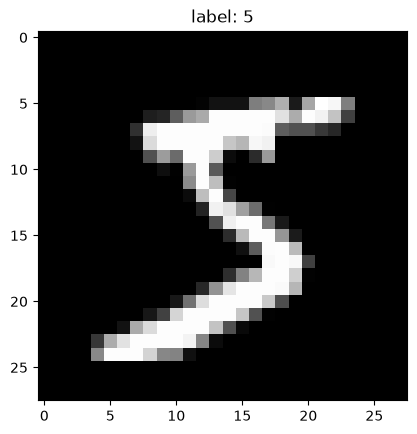

(784,) 0.0 1.0


In [2]:
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = mnist.load_data()
# (x_train[0], y_train[0]) = ([image of 5], 5)
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

plt.imshow(x_train[0], cmap="gray")
plt.title("label: " + str(y_train[0]))
plt.show()

x = x_train[0].reshape(784) / 255
print(x.shape, x.min(), x.max())

In [4]:
import numpy as np
data = np.load("hand-written-digit-detection-model.npz")
weight_matrix_input_to_h1 = data["weight_matrix_input_to_h1"]
weight_matrix_h1_to_h2 = data["weight_matrix_h1_to_h2"]
weight_matrix_h2_to_output = data["weight_matrix_h2_to_output"]
bias_h1 = data["bias_h1"]
bias_h2 = data["bias_h2"]
bias_o = data["bias_o"]

# Initializing activation values

In [7]:
sigmoid = lambda x: (1 / (1 + np.exp(-x)))
x_input = x_train[0].flatten() / 255
z_h1 = sigmoid((weight_matrix_input_to_h1 @ x_input) + bias_h1)
z_h2 = sigmoid((weight_matrix_h1_to_h2 @ z_h1) + bias_h2)
z_o = sigmoid((weight_matrix_h2_to_output @ z_h2) + bias_o)

def forward_pass(image):
  global x_input, z_h1, z_h2, z_o, weight_matrix_input_to_h1, weight_matrix_h1_to_h2, weight_matrix_h2_to_output
  x_input = image.flatten() / 255
  sigmoid = lambda x: (1 / (1 + np.exp(-x)))
  z_h1 = sigmoid((weight_matrix_input_to_h1 @ x_input) + bias_h1)
  z_h2 = sigmoid((weight_matrix_h1_to_h2 @ z_h1) + bias_h2)
  z_o = sigmoid((weight_matrix_h2_to_output @ z_h2) + bias_o)

In [8]:
def test_prediction(image_no: int):
  plt.title(f"Number: {y_test[image_no]}")
  plt.imshow(x_test[image_no], cmap="gray")
  forward_pass(x_test[image_no])
  print(f"Predicted: {np.argmax(z_o)}")

Predicted: 9


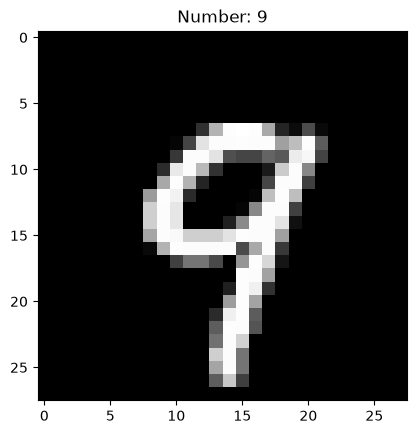

In [11]:
test_prediction(12)